# 03 · LCD: professor, solver, aluno e EMA

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


A célula abaixo executa uma atualização real de LCD em uma **cópia em memória** do aluno salvo. Ela não substitui os checkpoints nem as métricas entregues. O alvo EMA é congelado, mas atualizado por média dos pesos.

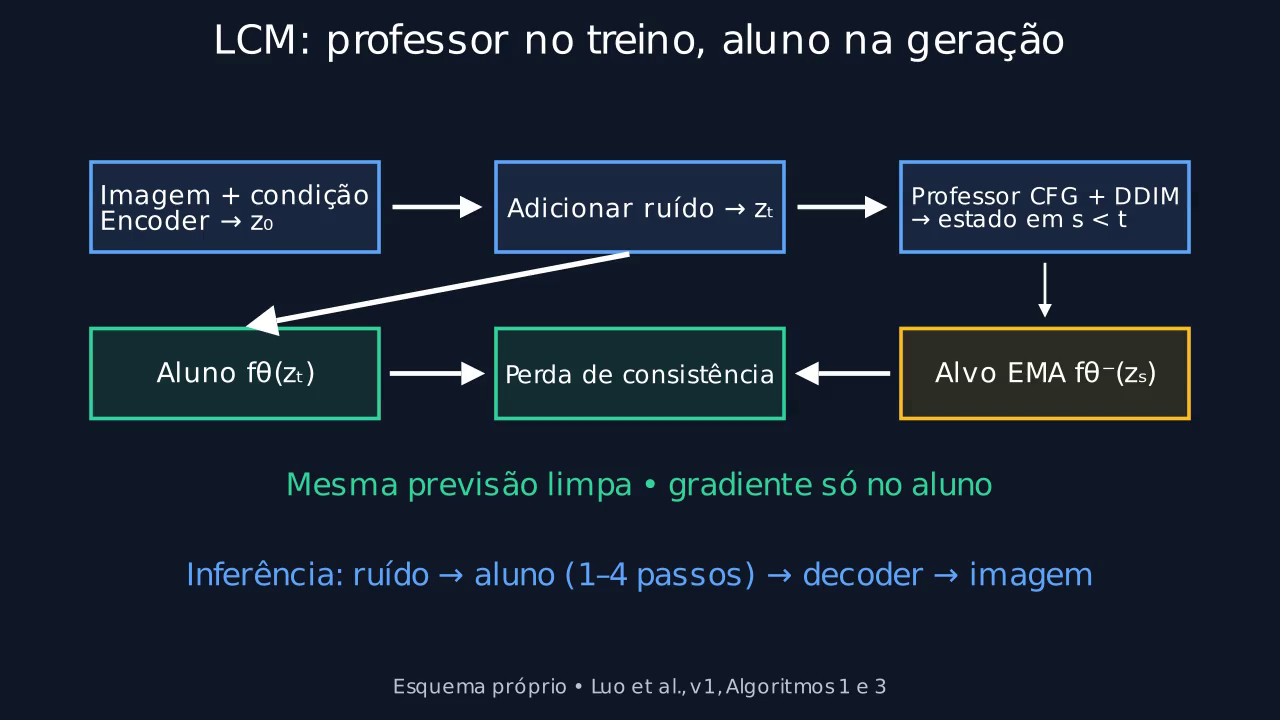

In [2]:
display(Image(filename=str(ROOT / 'assets/images/PipelineLCM.png')))

In [3]:
import copy
data = exp.prepare_data()
teacher = exp.NoiseMLP(config)
teacher.load_state_dict(torch.load(ROOT / 'experiments/checkpoints/teacher.pt', weights_only=True)['state_dict'])
teacher.eval().requires_grad_(False)
online = copy.deepcopy(teacher).train().requires_grad_(True)
target = copy.deepcopy(teacher).eval().requires_grad_(False)
torch.manual_seed(11)
ids = torch.randperm(len(data['train_images']))[:16]
z0 = torch.tensor((data['train_images'] - data['mean']) @ data['basis'].T / data['scales'])[ids]
labels = torch.tensor(data['train_labels'])[ids]
a, s = exp.schedule()
t = torch.randint(20, 1001, (16,))
low = t - 20
w = torch.rand(16) * 2
noisy = a[t, None] * z0 + s[t, None] * torch.randn_like(z0)
with torch.no_grad():
    epsilon = (1+w[:, None])*teacher(noisy,t,labels) - w[:, None]*teacher(noisy,t,torch.full_like(labels,10))
    earlier = exp.ddim_step(noisy, epsilon, t, low, a, s)
    goal = exp.consistency(target, earlier, low, labels, w, a, s)
prediction = exp.consistency(online, noisy, t, labels, w, a, s)
loss = torch.nn.functional.mse_loss(prediction, goal)
optimizer = torch.optim.Adam(online.parameters(), lr=config['student_lr'])
optimizer.zero_grad()
loss.backward()
print('Loss:', loss.item(), 'alvo requer gradiente:', goal.requires_grad)
assert all(p.grad is None for p in teacher.parameters())
assert all(p.grad is None for p in target.parameters())
assert any(p.grad is not None for p in online.parameters())
optimizer.step()
exp.ema_update(target, online, config['ema'])
print('Uma atualização LCD e EMA executada, sem alterar checkpoints.')

Loss: 0.013139134272933006 alvo requer gradiente: False
Uma atualização LCD e EMA executada, sem alterar checkpoints.


Inspecione `experiments/scripts/experiment.py`: `ddim_step` devolve o estado final. A função Ψ do artigo representa o incremento. Somar novamente o latente ao estado final seria incorreto.